In [48]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

# Data Extraction

In [3]:
from ucimlrepo import fetch_ucirepo  # pip install ucimlrepo
  
# fetch dataset 
bone_marrow_transplant_children = fetch_ucirepo(id=565) 
  
# data (as pandas dataframes) 
X = bone_marrow_transplant_children.data.features 
y = bone_marrow_transplant_children.data.targets 
  

# Exploratory Data Analysis

The data set describes pediatric patients with several hematologic diseases, who were subject to unrelated donor stem cell transplantation.

This dataset was originally used to identify the most important factors regarding the success or failure of the transplantation procedure.

In [4]:
bone_marrow_transplant_children.metadata # Provides basic dataset information

{'uci_id': 565,
 'name': 'Bone marrow transplant: children',
 'repository_url': 'https://archive.ics.uci.edu/dataset/565/bone+marrow+transplant+children',
 'data_url': 'https://archive.ics.uci.edu/static/public/565/data.csv',
 'abstract': 'The data set describes pediatric patients with several hematologic diseases, who were subject to the unmanipulated allogeneic unrelated donor hematopoietic stem cell transplantation.',
 'area': 'Health and Medicine',
 'tasks': ['Classification', 'Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 187,
 'num_features': 36,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Gender', 'Age'],
 'target_col': ['survival_status'],
 'index_col': None,
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 2020,
 'last_updated': 'Fri Nov 03 2023',
 'dataset_doi': '10.24432/C5NP6Z',
 'creators': ['Marek Sikora', 'Łukasz Wróbel', 'Adam Gudyś'],
 'intro_paper': {'ID': 293,
  'type': 'NATIVE',
  'titl

We are dealing with 187 training instances and 36 total features. As the number of training instances is small we should be careful in case of overfitting. Moreover, wee have 36 dimensions which is of high complexity specially considering that we are dealing with a low number of instances. Therefore, data reduction techniques will have to be applied.

The dataset contains missing values given by the value "NaN", we will have to take this into account.

The aim was to verify the hypothesis that increased dosage of CD34+ cells / kg extends overall survival time without simultaneous occurrence of undesirable events affecting patients' quality of life

In [5]:
bone_marrow_transplant_children.variables # Provides a description of all the different variables in the dataset

,name,role,type,demographic,description,units,missing_values
0,Recipientgender,Feature,Binary,Gender,"Male - 1, Female - 0",NaN,no
1,Stemcellsource,Feature,Binary,NaN,Source of hematopoietic stem cells (Peripheral...,NaN,no
2,Donorage,Feature,Integer,Age,Age of the donor at the time of hematopoietic ...,NaN,no
3,Donorage35,Feature,Binary,Age,"Donor age <35 - 0, Donor age >=35 - 1",NaN,no
4,IIIV,Feature,Binary,NaN,Development of acute graft versus host disease...,NaN,no
5,Gendermatch,Feature,Binary,Gender,Compatibility of the donor and recipient accor...,NaN,no
6,DonorABO,Feature,Categorical,NaN,ABO blood group of the donor of hematopoietic ...,NaN,no
7,RecipientABO,Feature,Categorical,NaN,ABO blood group of the recipient of hematopoie...,NaN,yes
8,RecipientRh,Feature,Binary,NaN,Presence of the Rh factor on recipient s red b...,NaN,yes
9,ABOmatch,Feature,Binary,NaN,Compatibility of the donor and the recipient o...,NaN,yes


## Redundant Variables

This link explains each of the [variables](https://archive.ics.uci.edu/dataset/565/bone+marrow+transplant+children). For this reason, we will first analyze what each of the variables mean, removing redundant variables, then, we will continue with EDA. For now, this variables will be removed, however, they can be inferred later again as some linear models may benefit from this.

First, we will remove the redundant variables, as they may induce a high collinearity.

- `Donorage`: Feature (Integer): Age of the donor
- `Donorage35`: Binary variable determining if donor age is higher or lower than 35.

As the first one, contains the same information and additional one, we will remove Donorage35.

- `DonorABO`: ABO blood group of the donor
- `RecipientABO`: ABO blood group of the recipient
- `ABOmatch`: Binary variable, if blood cells are compatible 

Third feature can be obtained from the previous two, we will remove it.

- `DonorCMV`: Binary -> Presence of cytomegalovirus infection in the donor of hematopoietic stem cells prior to transplantation (present, absent)
- `RecipientCMV`: Binary -> Presence of cytomegalovirus infection in the donor of hematopoietic stem cells prior to transplantation (present, absent)
- `CMVstatus`: Categorical -> Compatibility of DonorCMV and RecipientC

Same reason as before, redundant information which can be inferred, we will remove CMVstatus

- `Disease`: Feature Categorical. Type of disease, options include nonmalignant, the rest are malignant
- `Diseasegroup`: Either malignant or non-malignant.

Can be inferred from disease, we will remove it

- `HLAMismatch` is a boolean flag which can be derived from other columns. HLAmismatch = 0, whenever HLAmatch = 0, it will be a 1, when the other variable is higher than 0.

We can also remove recipientAge.

- `Recipientage`: Age of the recipient cells at the time of transplantation
- `RecipientAge10`: Binary, whether the age is higher or lower than 10
- `Recipientageint`: Feature Categorical, splits recipient age in bins.

We will remove the last 2 columns here

- `CD3_to_CD34_ration`: CD3+ to CD34+ ration, can be inferred from those 2 columns.

Finally, the variable `survival_time` is treated as a feature. However, as we are dealing with survival analysis, we have to model both the duration until an event occurs or the observation ends (survival time) and the event indicator (whether the event happened or not). For this reason, we will convert to targets

In [11]:
# Removing the redundant columns
cols = ["Donorage35", "ABOmatch", "CMVstatus", "Diseasegroup", "Recipientageint", "Recipientage10", "HLAmismatch", "CD3dCD34", "survival_time"] 

feats = bone_marrow_transplant_children.data.features
targets = bone_marrow_transplant_children.data.targets

duration = feats["survival_time"]
event = targets["survival_status"]

y = pd.concat([duration, event], axis=1)

X = feats.drop(columns=cols)

In [12]:
X # Features in our dataset

,Recipientgender,Stemcellsource,Donorage,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,...,Recipientage,Relapse,aGvHDIIIIV,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV
0,1,1,22.830137,1,0,1,1.0,1.0,1.0,1.0,...,9.6,0,0,1.0,7.20,5.38,35.0,19,51,32
1,1,0,23.342466,1,0,-1,-1.0,1.0,0.0,0.0,...,4.0,1,1,1.0,4.50,0.41,20.6,16,37,1000000
2,1,0,26.394521,1,0,-1,-1.0,1.0,0.0,1.0,...,6.6,1,1,1.0,7.94,0.42,23.4,23,20,1000000
3,0,0,39.684932,1,0,1,2.0,1.0,1.0,0.0,...,18.1,0,0,NaN,4.25,0.14,50.0,23,29,19
4,0,1,33.358904,0,0,1,2.0,0.0,0.0,1.0,...,1.3,0,1,1.0,51.85,13.05,9.0,14,14,1000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1,1,37.575342,1,0,1,1.0,0.0,1.0,1.0,...,12.9,1,0,1.0,11.08,4.39,44.0,15,22,16
183,0,1,22.895890,0,0,1,0.0,1.0,0.0,1.0,...,13.9,0,1,1.0,4.64,4.47,44.5,12,30,1000000
184,0,1,27.347945,1,0,1,-1.0,1.0,1.0,1.0,...,10.4,0,1,1.0,7.73,4.73,33.0,16,16,1000000
185,1,1,27.780822,1,0,1,0.0,1.0,0.0,0.0,...,8.0,0,0,0.0,15.41,1.91,24.0,13,14,54


In [13]:
y # Describes survival state, binary, 0 -alive 1-dead. As well as survival time

,survival_time,survival_status
0,999,0
1,163,1
2,435,1
3,53,1
4,2043,0
...,...,...
182,385,1
183,634,1
184,1895,0
185,382,1


In [14]:
# Inspecting the full dataset, combining features and targets
data = pd.concat([X,y], axis = 1)
data

,Recipientgender,Stemcellsource,Donorage,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,...,aGvHDIIIIV,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,survival_time,survival_status
0,1,1,22.830137,1,0,1,1.0,1.0,1.0,1.0,...,0,1.0,7.20,5.38,35.0,19,51,32,999,0
1,1,0,23.342466,1,0,-1,-1.0,1.0,0.0,0.0,...,1,1.0,4.50,0.41,20.6,16,37,1000000,163,1
2,1,0,26.394521,1,0,-1,-1.0,1.0,0.0,1.0,...,1,1.0,7.94,0.42,23.4,23,20,1000000,435,1
3,0,0,39.684932,1,0,1,2.0,1.0,1.0,0.0,...,0,NaN,4.25,0.14,50.0,23,29,19,53,1
4,0,1,33.358904,0,0,1,2.0,0.0,0.0,1.0,...,1,1.0,51.85,13.05,9.0,14,14,1000000,2043,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1,1,37.575342,1,0,1,1.0,0.0,1.0,1.0,...,0,1.0,11.08,4.39,44.0,15,22,16,385,1
183,0,1,22.895890,0,0,1,0.0,1.0,0.0,1.0,...,1,1.0,4.64,4.47,44.5,12,30,1000000,634,1
184,0,1,27.347945,1,0,1,-1.0,1.0,1.0,1.0,...,1,1.0,7.73,4.73,33.0,16,16,1000000,1895,0
185,1,1,27.780822,1,0,1,0.0,1.0,0.0,0.0,...,0,0.0,15.41,1.91,24.0,13,14,54,382,1


We currently have 187 rows with 29 different columns. 27 of them correspond to features, where the remaining ones are the targets

## Data Distribution

We have integer, binary and categorical variables. Plotting their different values

In [ ]:
overview = pd.DataFrame({
    "dtype": X.dtypes,
    "n_unique": X.nunique(),
    "missing_%": (X.isna().mean() * 100).round(1), # We already know targets have no missing values
})
print(overview.sort_values("n_unique"))

                        dtype  n_unique  missing_%
Recipientgender         int64         2        0.0
Stemcellsource          int64         2        0.0
IIIV                    int64         2        0.0
Gendermatch             int64         2        0.0
RecipientRh           float64         2        1.1
Riskgroup               int64         2        0.0
RecipientCMV          float64         2        7.5
DonorCMV              float64         2        1.1
Txpostrelapse           int64         2        0.0
extcGvHD              float64         2       16.6
Relapse                 int64         2        0.0
aGvHDIIIIV              int64         2        0.0
HLAmatch                int64         4        0.0
Antigen               float64         4        0.5
DonorABO                int64         4        0.0
RecipientABO          float64         4        0.5
Disease                   str         5        0.0
Allele                float64         5        0.5
HLAgrI                  int64  

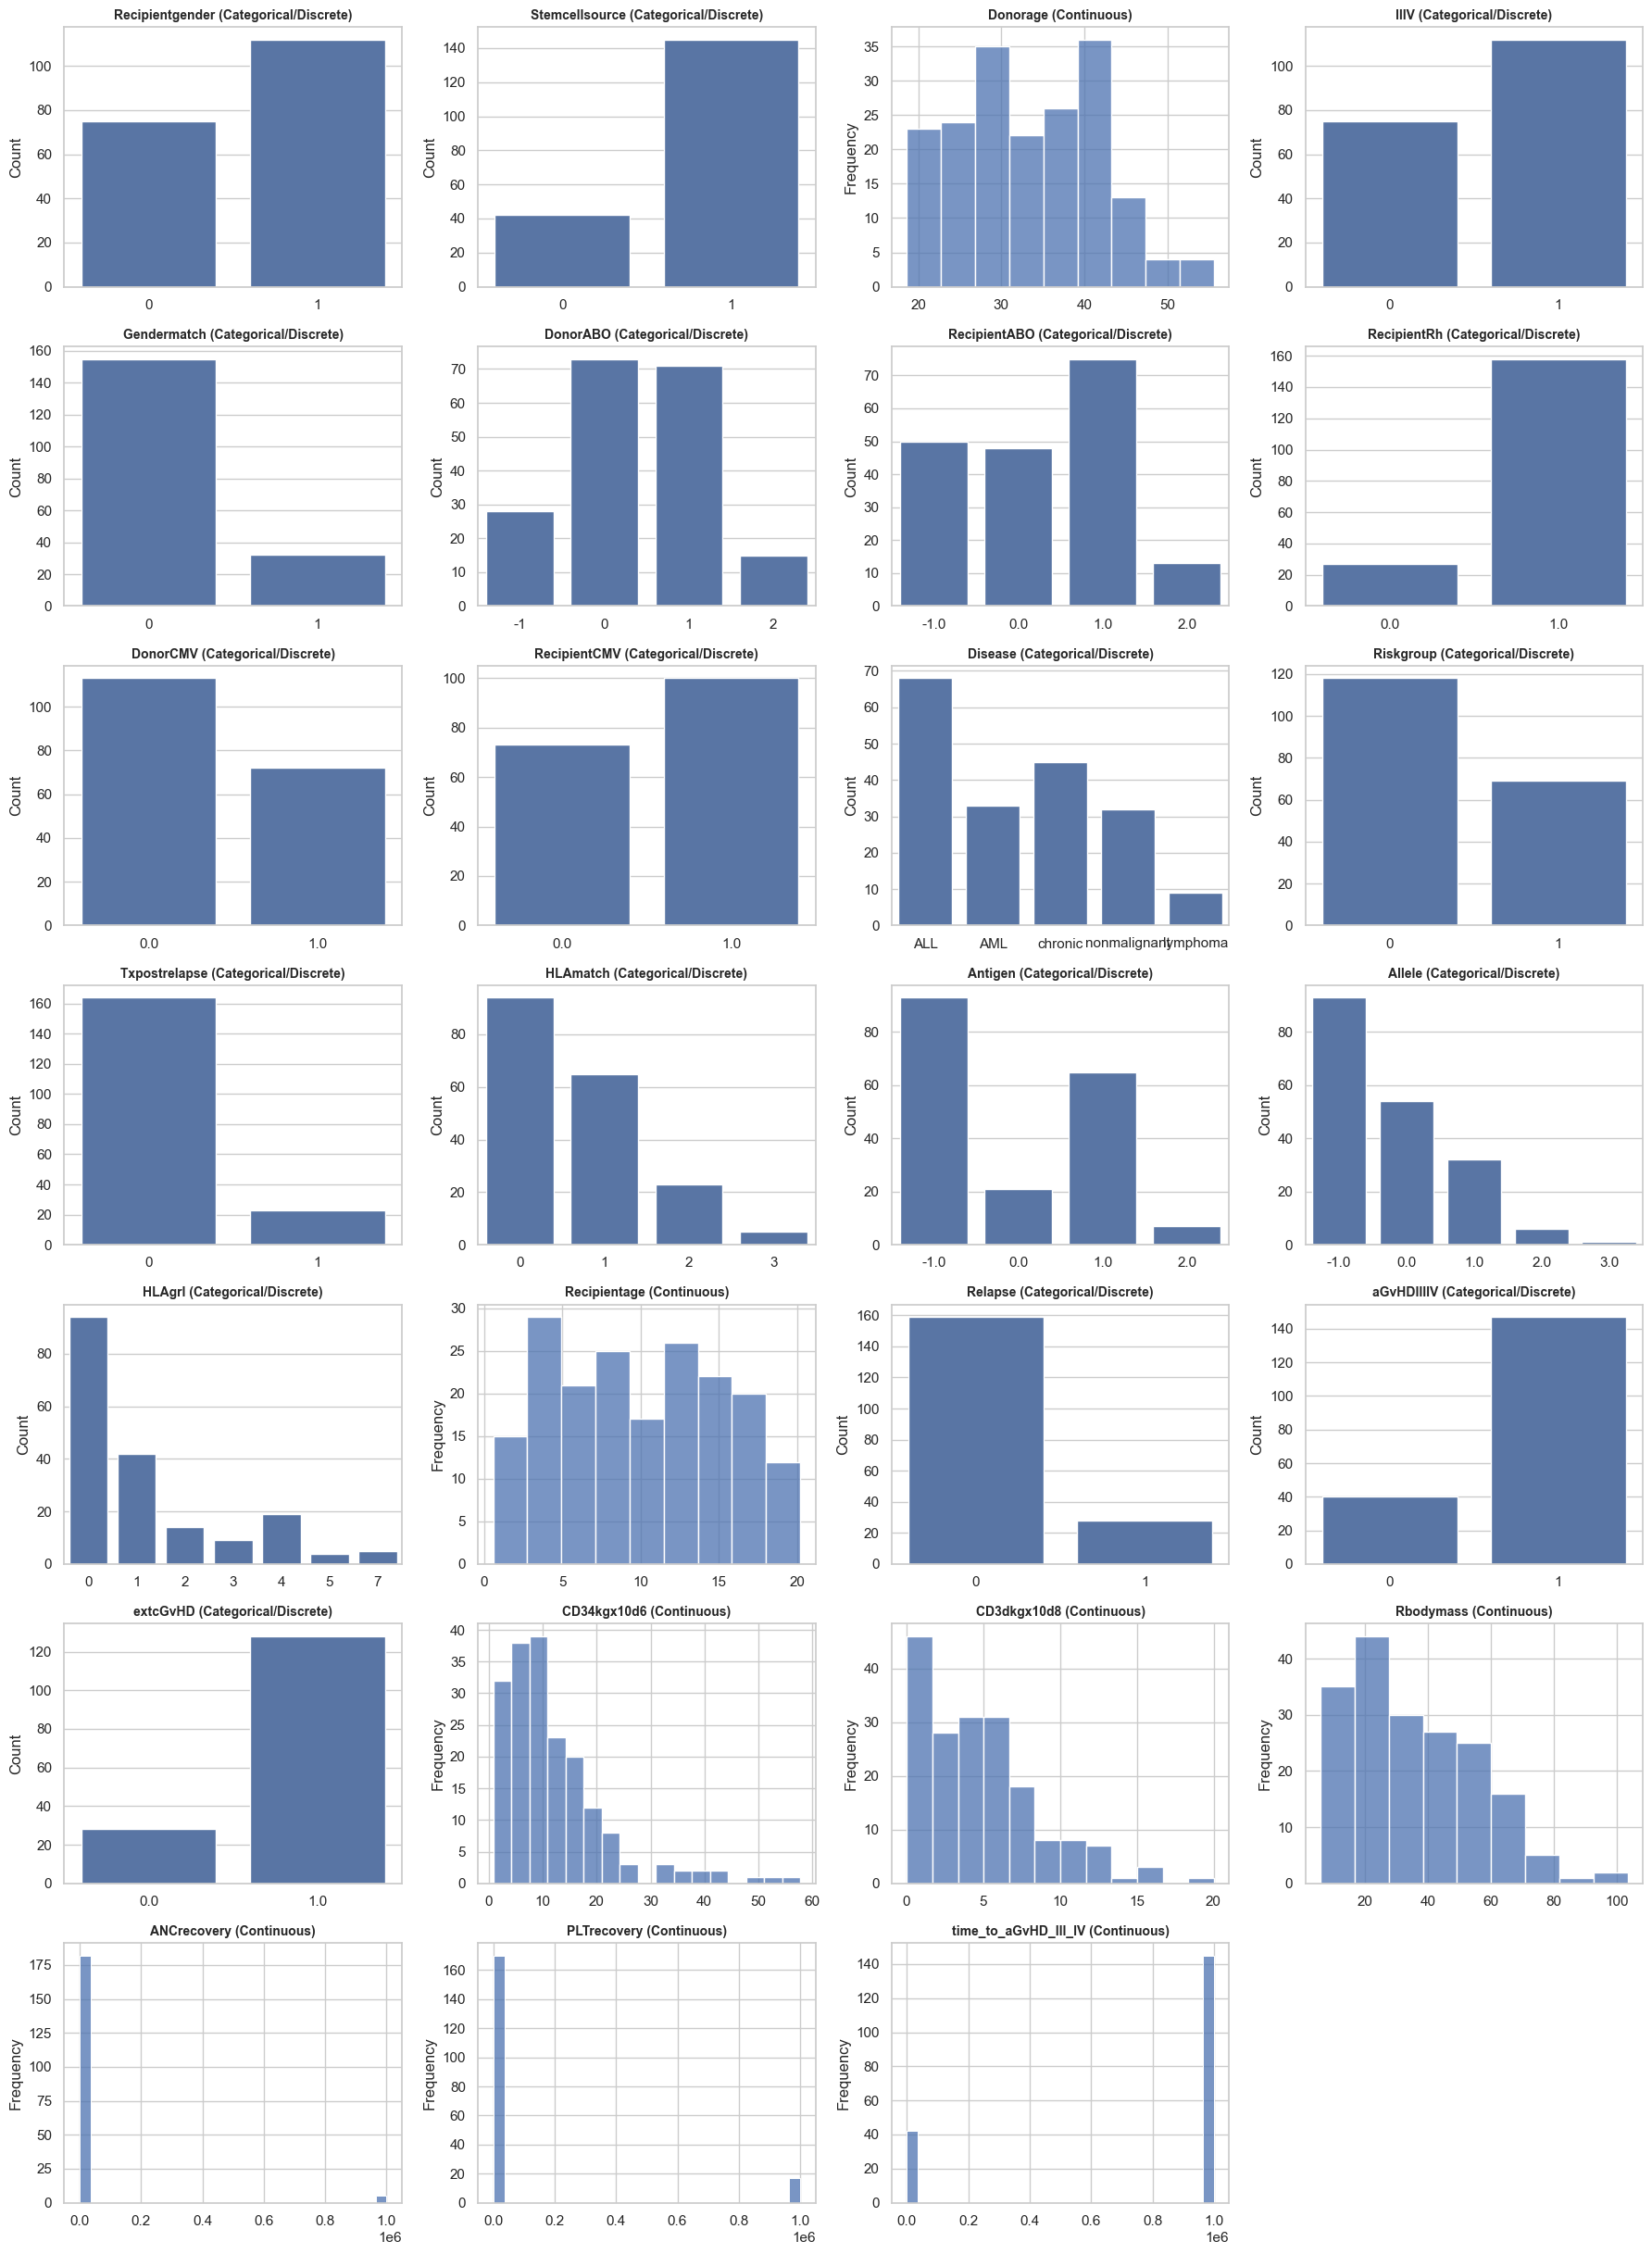

In [23]:
sns.set_theme(style="whitegrid")

# Define grid size dynamically
num_vars = len(X.columns)
ncols = 4
nrows = math.ceil(num_vars / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = axes.flatten()

# Plot each variable based on cardinality
for i, col in enumerate(X.columns):
    ax = axes[i]
    if X[col].nunique() <= 10:
        sns.countplot(data=X, x=col, ax=ax)
        ax.set_title(f"{col} (Categorical/Discrete)", fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Count")
    else:
        sns.histplot(data=X, x=col,  ax=ax)
        ax.set_title(f"{col} (Continuous)", fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Frequency")

# Hide extra empty subplots in the grid
for j in range(num_vars, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Missing Values



extcGvHD        16.577540
RecipientCMV     7.486631
CD3dkgx10d8      2.673797
RecipientRh      1.069519
Rbodymass        1.069519
DonorCMV         1.069519
RecipientABO     0.534759
Antigen          0.534759
Allele           0.534759
dtype: float64


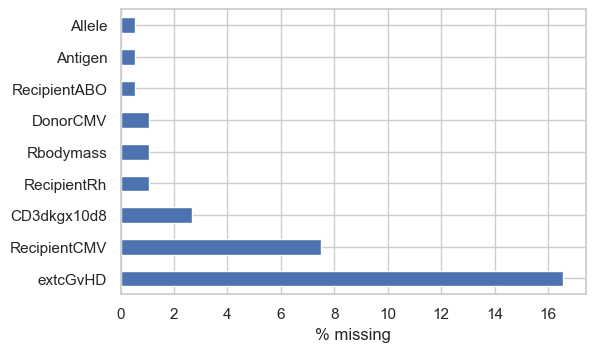

In [26]:
missing_pct = (X.isna().mean() * 100).sort_values(ascending=False)
miss = missing_pct[missing_pct > 0]
print(miss)

miss.plot.barh(figsize=(6, 0.3 * len(miss) + 1))
plt.xlabel("% missing"); plt.show()

As we have binary, continuous and categorical variables.

For variables which have less than 3% of missing values, we will use mode imputation, just in case, to avoid 0.5 values. For Continuous Variables, we will use median imputation.

For remaining variables, we will use an Iterative Imputer with Random Forests.

In [32]:
# Encoding strings for RF
X_encoded = pd.get_dummies(X, columns=["Disease"], drop_first=True)

# Variables with < 3% missingness
mode_cols = ["RecipientRh", "DonorCMV", "Antigen", "RecipientABO", "Allele"]
median_cols = ["Rbodymass", "CD3dkgx10d8"]

# Variables with >3% missingness
rf_binary_cols = ["RecipientCMV", "extcGvHD"]

X_imputed = X_encoded.copy()

if mode_cols:
    mode_imp = SimpleImputer(strategy="most_frequent")
    X_imputed[mode_cols] = mode_imp.fit_transform(X_imputed[mode_cols])

if median_cols:
    median_imp = SimpleImputer(strategy="median")
    X_imputed[median_cols] = median_imp.fit_transform(X_imputed[median_cols])

rf_imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=100, random_state=42),
    max_iter=10,
    random_state=42,
)

X_final = pd.DataFrame(
    rf_imputer.fit_transform(X_imputed), columns=X_imputed.columns
)

# Rounding just in case for binary columns
for col in rf_binary_cols:
    X_final[col] = X_final[col].round().astype(int)


In [35]:
print(X_final.isna().sum().sum())
X_final

0


,Recipientgender,Stemcellsource,Donorage,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,DonorCMV,RecipientCMV,...,CD34kgx10d6,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,Disease_AML,Disease_chronic,Disease_lymphoma,Disease_nonmalignant
0,1.0,1.0,22.830137,1.0,0.0,1.0,1.0,1.0,1.0,1,...,7.20,5.38,35.0,19.0,51.0,32.0,0.0,0.0,0.0,0.0
1,1.0,0.0,23.342466,1.0,0.0,-1.0,-1.0,1.0,0.0,0,...,4.50,0.41,20.6,16.0,37.0,1000000.0,0.0,0.0,0.0,0.0
2,1.0,0.0,26.394521,1.0,0.0,-1.0,-1.0,1.0,0.0,1,...,7.94,0.42,23.4,23.0,20.0,1000000.0,0.0,0.0,0.0,0.0
3,0.0,0.0,39.684932,1.0,0.0,1.0,2.0,1.0,1.0,0,...,4.25,0.14,50.0,23.0,29.0,19.0,1.0,0.0,0.0,0.0
4,0.0,1.0,33.358904,0.0,0.0,1.0,2.0,0.0,0.0,1,...,51.85,13.05,9.0,14.0,14.0,1000000.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,1.0,1.0,37.575342,1.0,0.0,1.0,1.0,0.0,1.0,1,...,11.08,4.39,44.0,15.0,22.0,16.0,0.0,0.0,1.0,0.0
183,0.0,1.0,22.895890,0.0,0.0,1.0,0.0,1.0,0.0,1,...,4.64,4.47,44.5,12.0,30.0,1000000.0,1.0,0.0,0.0,0.0
184,0.0,1.0,27.347945,1.0,0.0,1.0,-1.0,1.0,1.0,1,...,7.73,4.73,33.0,16.0,16.0,1000000.0,0.0,0.0,0.0,1.0
185,1.0,1.0,27.780822,1.0,0.0,1.0,0.0,1.0,0.0,0,...,15.41,1.91,24.0,13.0,14.0,54.0,0.0,1.0,0.0,0.0


In [36]:
# Undoing the disease one-hot encoding
disease_cols = [c for c in X_final.columns if c.startswith("Disease_")]

X_final["Disease"] = X_final[disease_cols].idxmax(axis=1).str.replace(
    "Disease_", ""
)

X_final.loc[X_final[disease_cols].sum(axis=1) == 0, "Disease"] = "ALL"

X_final = X_final.drop(columns=disease_cols)

Missing values have been correctly removed

## Correlation Matrix

Obtaining a correlation matrix between the features and the targets to evaluate impact of certain features on the target column.

We will use both Pearson and Spearman, as Pearson assumes data normality as well as a linear relationship. On the other hand, Spearman does not make any data assumption, it is robust to outliers and it measures if both variables tend to move in the same direction (not necessarily linear)

In [45]:
# Correlation to the two target variables
X_corr = X_final.copy()
X_corr["Disease"] = X_corr["Disease"].astype("category").cat.codes
target = y["survival_time"] 

pearson_corr = X_corr.corrwith(target, method="pearson")
spearman_corr = X_corr.corrwith(target, method="spearman")

# Compute correlation against survival_status (binary event)
pearson_status = X_corr.corrwith(y["survival_status"], method="pearson")
spearman_status = X_corr.corrwith(y["survival_status"], method="spearman")

# Combined overview table for both targets
all_corrs_abs = (
    pd.DataFrame(
        {
            "time_spearman": spearman_corr.abs(),
            "time_pearson": pearson_corr.abs(),
            "status_spearman": spearman_status.abs(),
            "status_pearson": pearson_status.abs(),
        }
    )
)

print(all_corrs_abs.head())


                 time_spearman  time_pearson  status_spearman  status_pearson
Recipientgender       0.047499      0.060487         0.023905        0.023905
Stemcellsource        0.045815      0.041253         0.126335        0.126335
Donorage              0.013431      0.005603         0.046753        0.060384
IIIV                  0.035776      0.064272         0.067730        0.067730
Gendermatch           0.072467      0.110597         0.012962        0.012962


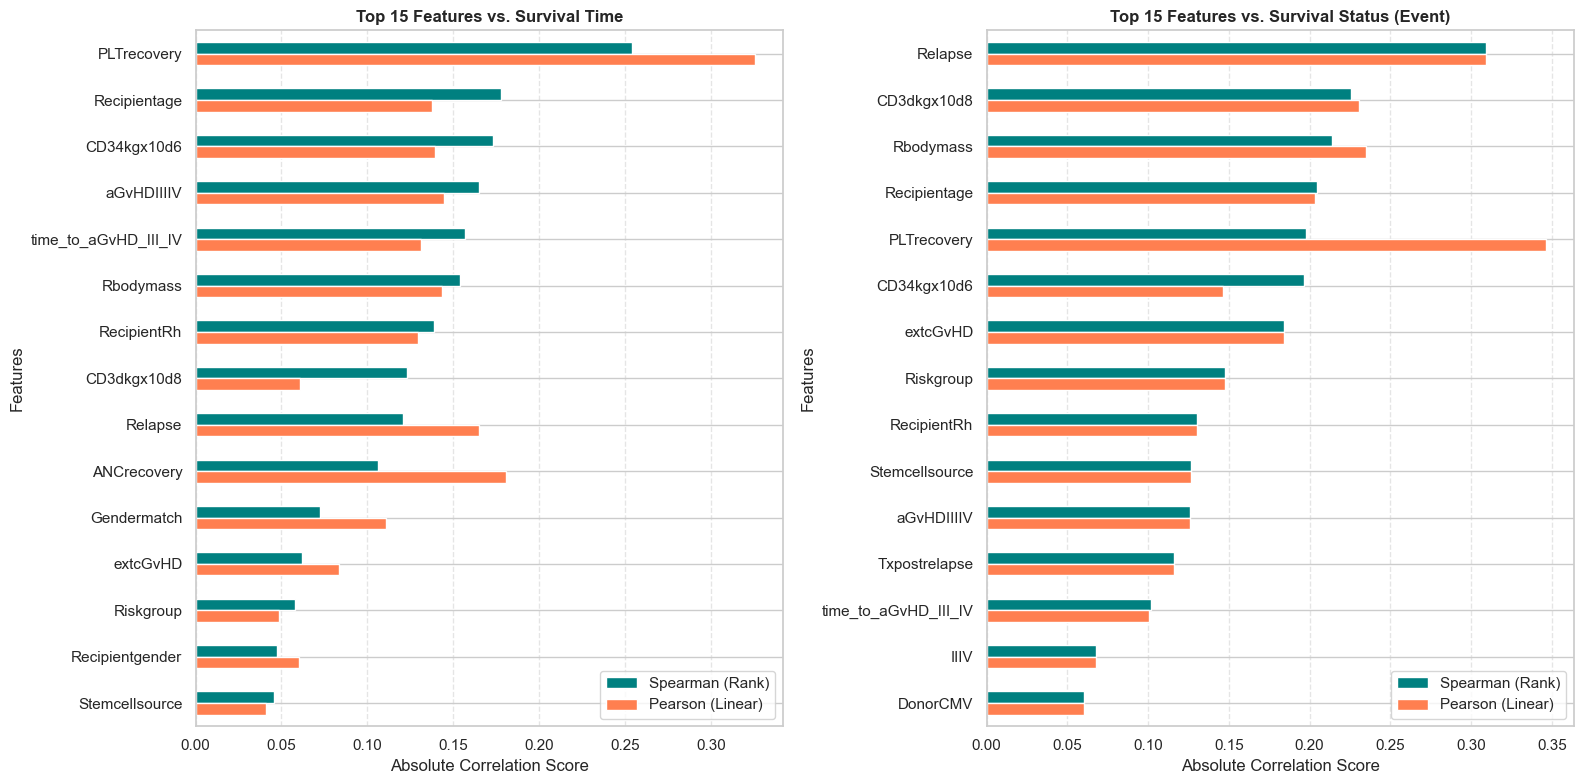

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top 15 survival time
top_time = all_corrs_abs.sort_values(
    by="time_spearman", ascending=False
).head(15)
top_time[["time_spearman", "time_pearson"]].plot(
    kind="barh", ax=axes[0], color=["teal", "coral"]
)
axes[0].invert_yaxis()
axes[0].set_title(
    "Top 15 Features vs. Survival Time", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Absolute Correlation Score")
axes[0].set_ylabel("Features")
axes[0].legend(["Spearman (Rank)", "Pearson (Linear)"])
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

top_status = all_corrs_abs.sort_values(
    by="status_spearman", ascending=False
).head(15)
top_status[["status_spearman", "status_pearson"]].plot(
    kind="barh", ax=axes[1], color=["teal", "coral"]
)
axes[1].invert_yaxis()
axes[1].set_title(
    "Top 15 Features vs. Survival Status (Event)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Absolute Correlation Score")
axes[1].set_ylabel("Features")
axes[1].legend(["Spearman (Rank)", "Pearson (Linear)"])
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Just in case, we will implement a small tree model with permutation importance as a next step in order to obtain more robustness in this analysis

In [50]:
X_enc = X_final.copy()
for c in X_enc.select_dtypes(["object", "string", "category"]).columns:
    X_enc[c] = X_enc[c].astype("category")

y_event = y["survival_status"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y_event, test_size=0.3, stratify=y_event, random_state=0
)

model = HistGradientBoostingClassifier(
    categorical_features="from_dtype", random_state=0
)
model.fit(X_train, y_train)

result = permutation_importance(
    model, X_test, y_test, n_repeats=30, random_state=0, scoring="roc_auc"
)
perm_imp = pd.Series(result.importances_mean, index=X_enc.columns)

perm_imp

Recipientgender         0.003557
Stemcellsource          0.000000
Donorage                0.047560
IIIV                    0.000000
Gendermatch             0.000000
DonorABO               -0.005045
RecipientABO            0.001489
RecipientRh             0.000000
DonorCMV                0.001944
RecipientCMV           -0.003515
Riskgroup               0.000207
Txpostrelapse           0.000000
HLAmatch               -0.017080
Antigen                 0.000000
Allele                  0.000000
HLAgrI                  0.000000
Recipientage           -0.003019
Relapse                 0.000000
aGvHDIIIIV              0.014971
extcGvHD                0.000000
CD34kgx10d6             0.037097
CD3dkgx10d8             0.003226
Rbodymass              -0.008809
ANCrecovery             0.039702
PLTrecovery             0.013648
time_to_aGvHD_III_IV    0.000000
Disease                -0.007734
dtype: float64

## Relevant Features

Combining feature importance and correlation values we will select the most important variables.

This methods allow us to detect non-linear relationships, it also evaluates the impact of both target variables and it provides robustness as it applies it on different methods.

In [53]:
feature_metrics = pd.DataFrame(
    {
        "time_spearman": spearman_corr.abs(),
        "time_pearson": pearson_corr.abs(),
        "status_spearman": spearman_status.abs(),
        "status_pearson": pearson_status.abs(),
        "perm_importance": perm_imp.clip(
            lower=0
        ),# Negative values to 0
    }
).fillna(0)

# Normalize each column to a [0, 1] scale for equal weighting
norm_df = feature_metrics.apply(
    lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9)
)

# Calculating a mixed score with equal weights to all values
feature_metrics["composite_score"] = (
    0.2*norm_df["time_pearson"]
    + 0.2 * norm_df["time_spearman"]
    + 0.2 * norm_df["status_spearman"]
    + 0.2 * norm_df["status_pearson"]
    + 0.2 * norm_df["perm_importance"]
)

# Rank features by composite score
feature_summary = feature_metrics.sort_values(
    by="composite_score", ascending=False
).round(4)

print(feature_summary)

                      time_spearman  time_pearson  status_spearman  \
PLTrecovery                  0.2539        0.3258           0.1976   
CD34kgx10d6                  0.1733        0.1393           0.1965   
Relapse                      0.1205        0.1648           0.3092   
ANCrecovery                  0.1064        0.1810           0.0446   
Rbodymass                    0.1538        0.1434           0.2137   
Recipientage                 0.1780        0.1376           0.2046   
aGvHDIIIIV                   0.1651        0.1447           0.1262   
CD3dkgx10d8                  0.1228        0.0607           0.2255   
RecipientRh                  0.1391        0.1298           0.1306   
time_to_aGvHD_III_IV         0.1568        0.1312           0.1016   
extcGvHD                     0.0619        0.0838           0.1841   
Donorage                     0.0134        0.0056           0.0468   
Riskgroup                    0.0578        0.0488           0.1477   
Stemcellsource      

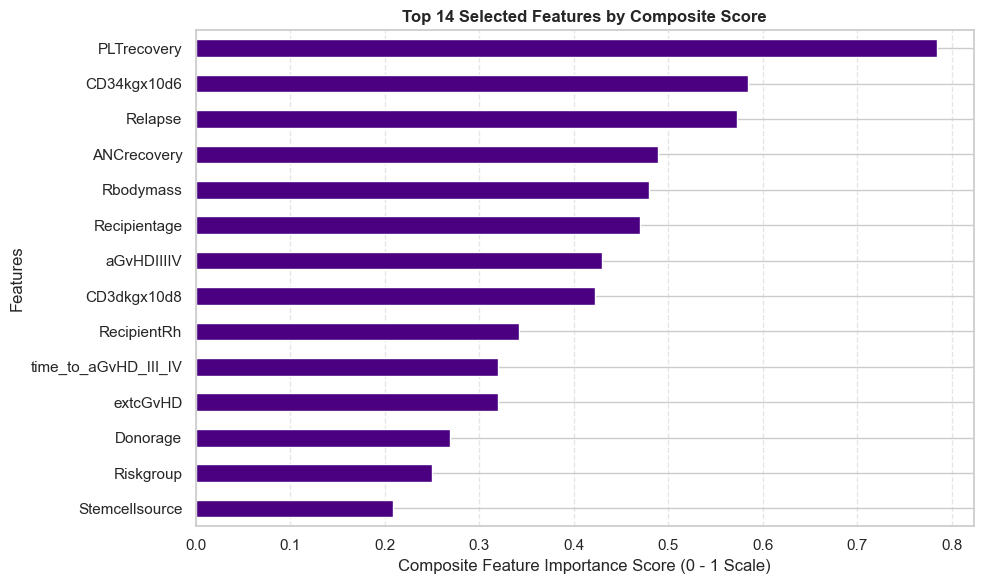

In [55]:
plt.figure(figsize=(10, 6))
feature_summary["composite_score"].head(14).plot(
    kind="barh", color="indigo"
).invert_yaxis()
plt.title(
    "Top 14 Selected Features by Composite Score", fontsize=12, fontweight="bold"
)
plt.xlabel("Composite Feature Importance Score (0 - 1 Scale)")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [57]:
# We cutoff features below a 0.2 composite score. We see there is a 0.06 gap between variables here and this means that it does not rank high among all methods.
# This is 14 total features

selected_features = feature_summary.head(12).index.tolist()
X_selected = X_final[selected_features]
X_selected

,PLTrecovery,CD34kgx10d6,Relapse,ANCrecovery,Rbodymass,Recipientage,aGvHDIIIIV,CD3dkgx10d8,RecipientRh,time_to_aGvHD_III_IV,extcGvHD,Donorage
0,51.0,7.20,0.0,19.0,35.0,9.6,0.0,5.38,1.0,32.0,1,22.830137
1,37.0,4.50,1.0,16.0,20.6,4.0,1.0,0.41,1.0,1000000.0,1,23.342466
2,20.0,7.94,1.0,23.0,23.4,6.6,1.0,0.42,1.0,1000000.0,1,26.394521
3,29.0,4.25,0.0,23.0,50.0,18.1,0.0,0.14,1.0,19.0,1,39.684932
4,14.0,51.85,0.0,14.0,9.0,1.3,1.0,13.05,0.0,1000000.0,1,33.358904
...,...,...,...,...,...,...,...,...,...,...,...,...
182,22.0,11.08,1.0,15.0,44.0,12.9,0.0,4.39,0.0,16.0,1,37.575342
183,30.0,4.64,0.0,12.0,44.5,13.9,1.0,4.47,1.0,1000000.0,1,22.895890
184,16.0,7.73,0.0,16.0,33.0,10.4,1.0,4.73,1.0,1000000.0,1,27.347945
185,14.0,15.41,0.0,13.0,24.0,8.0,0.0,1.91,1.0,54.0,0,27.780822


We have reduced our total dataframe from 36 columns to a total of 12, through redundancy, handling missing values, correlation and permutation importance